In [2]:
2+2

4

In [1]:
import os
import json
from pathlib import Path

import random
import pandas as pd
import numpy as np
# import torch
import seaborn as sns
import matplotlib.pyplot as plt

import ast
import re


In [2]:
# Setting the max characters to be displayed
pd.set_option('display.max_colwidth', None)

# display full dataframe pandas / output window widened
pd.set_option('display.width', 10000) # None

# Setting the precision for float columns
pd.set_option('display.precision', 2)

In [3]:
result = pd.read_parquet("results/results_myvideos_2/logits_output_meta.parquet")
print(result.shape)
del result['top5_classes']
result.head(4)

(150, 12)


,video_id,cam,session,template,label,top1_pred,top1_class,top1_conf,top5_preds,correct_top1,correct_top5
0,260922-134214,cam0,plug_1,Plugging [something] into [something],3,3,Plugging [something] into [something],0.96,"[3, 0, 7, 6, 2]",True,True
1,260922-134214,cam1,plug_1,Plugging [something] into [something],3,3,Plugging [something] into [something],0.91,"[3, 0, 7, 5, 2]",True,True
2,260922-134214,cam2,plug_1,Plugging [something] into [something],3,3,Plugging [something] into [something],0.96,"[3, 0, 7, 4, 2]",True,True
3,260922-134301,cam0,plug_1,Plugging [something] into [something],3,3,Plugging [something] into [something],0.94,"[3, 0, 7, 4, 6]",True,True


In [4]:
d = np.load("results/results_myvideos_2/logits_output.npz", allow_pickle=True)
print(d["logits"].shape)   # (150, 10)
d

(150, 10)


NpzFile 'results/results_myvideos_2/logits_output.npz' with keys: logits, probs, labels, video_ids, cams...

# main result

In [11]:
from sklearn.metrics import balanced_accuracy_score
    
n = len(result)
top1_acc  = result["correct_top1"].mean()
top5_acc  = result["correct_top5"].mean()
ba_top1   = balanced_accuracy_score(result["label"], result["top1_pred"])

# Top-5 balanced: credit correct if label is anywhere in top-5
top5_pred_adj = [
    row["label"] if row["correct_top5"] else row["top5_preds"][0]
    for _, row in result.iterrows()
]
ba_top5 = balanced_accuracy_score(result["label"], top5_pred_adj)

my_metrics = {
    "total_evaluated":        n,
    "top1_accuracy":          round(top1_acc, 6),
    "top1_balanced_accuracy": round(ba_top1,  6),
    "top5_accuracy":          round(top5_acc, 6),
    "top5_balanced_accuracy": round(ba_top5,  6),
}
my_metrics

{'total_evaluated': 150,
 'top1_accuracy': np.float64(0.866667),
 'top1_balanced_accuracy': np.float64(0.866667),
 'top5_accuracy': np.float64(1.0),
 'top5_balanced_accuracy': np.float64(1.0)}

- cam0 = birds eye
- cam1 = POV
- cam2 = side view

In [12]:
result.groupby("cam")[["correct_top1", "correct_top5"]].mean().rename(
        columns={"correct_top1": "top1_acc", "correct_top5": "top5_acc"}
)

,top1_acc,top5_acc
cam,,
cam0,0.80,1.0
cam1,0.98,1.0
cam2,0.82,1.0


In [14]:
result.groupby("template")[["correct_top1", "correct_top5"]].mean().rename(
        columns={"correct_top1": "top1_acc", "correct_top5": "top5_acc"}
).sort_values("template")

,top1_acc,top5_acc
template,,
Attaching [something] to [something],0.87,1.0
Moving [something] up,1.00,1.0
Piling [something] up,1.00,1.0
Plugging [something] into [something],1.00,1.0
Pushing [something] with [something],1.00,1.0
Putting [something] next to [something],0.93,1.0
Putting [something] on a surface,0.60,1.0
Putting [something] onto [something],0.93,1.0
Showing a photo of [something] to the camera,0.33,1.0


In [76]:
result[result.cam=='cam1'].groupby("template")[["correct_top1", "correct_top5"]].mean().rename(
        columns={"correct_top1": "top1_acc", "correct_top5": "top5_acc"}
).sort_values("template")

,top1_acc,top5_acc
template,,
Attaching [something] to [something],1.00000,1.00000
Moving [something] up,1.00000,1.00000
Piling [something] up,1.00000,1.00000
Plugging [something] into [something],1.00000,1.00000
Pushing [something] with [something],1.00000,1.00000
Putting [something] next to [something],1.00000,1.00000
Putting [something] on a surface,0.80000,1.00000
Putting [something] onto [something],1.00000,1.00000
Showing a photo of [something] to the camera,1.00000,1.00000


# Granular analysis

##### Distractor objects -> expected spike in action/verb -- P(Action|Noun) estimate
- Plug -> Plugging [something] into [something] -- 55%
- lady/person -> Showing a photo of [something] to the camera -- 96%
- magnet -> Attaching [something] to [something] -- 60%
- Books -> Piling [something] up -- 55%
- (~) Paper -> Tearing [something] into two pieces -- 25%

##### id2label

In [30]:
id2label_list = [
    "Attaching [something] to [something]",
    "Moving [something] up",
    "Piling [something] up",
    "Plugging [something] into [something]",
    "Pushing [something] with [something]",
    "Putting [something] next to [something]",
    "Putting [something] on a surface",
    "Putting [something] onto [something]",
    "Showing a photo of [something] to the camera",
    "Tearing [something] into two pieces",
]

In [21]:
for k in d.keys():
    print(f"{k:11} {d[k].shape} -- {d[k][0:2]}")
    print("-"*50)

logits      (150, 10) -- [[ 8.125       1.7109375   2.421875   11.4375      1.3671875   1.5078125
   2.515625    6.28125    -2.3125     -3.515625  ]
 [ 8.1875      1.140625    2.         10.5625      0.64453125  2.546875
   1.734375    5.28125    -1.671875   -3.296875  ]]
--------------------------------------------------
probs       (150, 10) -- [[3.49368490e-02 5.72389617e-05 1.16532756e-04 9.59144831e-01
  4.05885039e-05 4.67170794e-05 1.27986190e-04 5.52781252e-03
  1.02408285e-06 3.07485436e-07]
 [8.46429244e-02 7.36498259e-05 1.73937631e-04 9.09997165e-01
  4.48457140e-05 3.00537271e-04 1.33362613e-04 4.62830858e-03
  4.42301598e-06 8.70943438e-07]]
--------------------------------------------------
labels      (150,) -- [3 3]
--------------------------------------------------
video_ids   (150,) -- ['260922-134214' '260922-134214']
--------------------------------------------------
cams        (150,) -- ['cam0' 'cam1']
--------------------------------------------------
sessions  

In [8]:
print("logit  prob")
for l, p in zip(d['logits'][0], d['probs'][0]):
    print(f"{str(l.round(2)):5}  {str(p.round(2)):5}")

logit  prob
8.12   0.03 
1.71   0.0  
2.42   0.0  
11.44  0.96 
1.37   0.0  
1.51   0.0  
2.52   0.0  
6.28   0.01 
-2.31  0.0  
-3.52  0.0  


In [11]:
result.head(1)

,video_id,cam,session,template,label,top1_pred,top1_class,top1_conf,top5_preds,correct_top1,correct_top5
0,260922-134214,cam0,plug_1,Plugging [something] into [something],3,3,Plugging [something] into [something],0.96,"[3, 0, 7, 6, 2]",True,True


In [15]:
df = result[['video_id',	'cam'	,'session'	,'template',	'label'	,'top1_pred',	'top1_class',	'top1_conf','correct_top1']]
print(df.shape)
df.head(2)

(150, 9)


,video_id,cam,session,template,label,top1_pred,top1_class,top1_conf,correct_top1
0,260922-134214,cam0,plug_1,Plugging [something] into [something],3,3,Plugging [something] into [something],0.96,True
1,260922-134214,cam1,plug_1,Plugging [something] into [something],3,3,Plugging [something] into [something],0.91,True


In [16]:
# Define class probability column names
class_cols = [f'prob_{i}' for i in range(10)]

# Convert probabilities array into a DataFrame using matching index
probs_df = pd.DataFrame(d['probs'], columns=class_cols, index=df.index)

# Combine metadata with class probabilities
df = pd.concat([df, probs_df], axis=1)
df.head(2)

,video_id,cam,session,template,label,top1_pred,top1_class,top1_conf,correct_top1,prob_0,prob_1,prob_2,prob_3,prob_4,prob_5,prob_6,prob_7,prob_8,prob_9
0,260922-134214,cam0,plug_1,Plugging [something] into [something],3,3,Plugging [something] into [something],0.96,True,0.03,5.72e-05,1.17e-04,0.96,4.06e-05,4.67e-05,1.28e-04,5.53e-03,1.02e-06,3.07e-07
1,260922-134214,cam1,plug_1,Plugging [something] into [something],3,3,Plugging [something] into [something],0.91,True,0.08,7.36e-05,1.74e-04,0.91,4.48e-05,3.01e-04,1.33e-04,4.63e-03,4.42e-06,8.71e-07


#### Main Analysis 
Comparison of:
- P(label=3|session=plug_1) -- should be high.
- P(label=3|session=plug_2) -- if its high it means plug as distractor is increasing probabilty of label=3.
- P(label=3|session not like 'plug%')

In [39]:
distractor = 'plug'
label = 3

prob_col = f'prob_{label}'

df['session_temp'] = np.where(df['session'] == f'{distractor}_1', "Normal",
                     np.where(df['session'] == f'{distractor}_2', f"distractor_{distractor}", 'Baseline'))
              
df.groupby(['session','session_temp']).agg(
    videos=('video_id', 'count'),
).reset_index()


,session,session_temp,videos
0,books_1,Baseline,15
1,books_2,Baseline,15
2,lady_1,Baseline,15
3,lady_2,Baseline,15
4,magnet_1,Baseline,15
5,magnet_2,Baseline,15
6,paper_1,Baseline,15
7,paper_2,Baseline,15
8,plug_1,Normal,15
9,plug_2,distractor_plug,15


In [40]:
df.groupby(['session_temp']).agg(
    videos=('video_id', 'count'),
    prob=(prob_col, 'mean')
).sort_values('session_temp').reset_index()

,session_temp,videos,prob
0,Baseline,120,1.86e-02
1,Normal,15,8.91e-01
2,distractor_plug,15,5.23e-04


In [48]:
pd.set_option('display.float_format',  '{:,.6f}'.format)
df.groupby(['session_temp']).agg(
    videos=('video_id', 'count'),
    prob=(prob_col, 'mean')
).sort_values('session_temp').reset_index()

,session_temp,videos,prob
0,Baseline,120,0.018577
1,Normal,15,0.890952
2,distractor_plug,15,0.000523


In [74]:
pd.set_option('display.float_format',  '{:,.5f}'.format)

def avg_prob_in_diff_cases(df:pd.DataFrame, distractor:str, label:int, id2label_list:list, cams:list):
    prob_col = f'prob_{label}'

    df['session_temp'] = np.where(df['session'] == f'{distractor}_1', "Normal",
                        np.where(df['session'] == f'{distractor}_2', f"distractor_{distractor}", 'Baseline'))
    
    r = df[df['cam'].isin(cams)].groupby(['session_temp']).agg(
        videos=('video_id', 'count'),
        prob_mean=(prob_col, 'mean'),
        prob_std=(prob_col, 'std'),
        examples=('video_id', lambda x: ', '.join(map(str, x.unique()[0:3]))),
    ).sort_values('session_temp').reset_index()

    print("-"*20, distractor, "-"*20)
    print(f"label {label}: {id2label_list[label]}")
    print(f"cams used: {cams}")
    print(r)

In [75]:
avg_prob_in_diff_cases(df, distractor='plug', label=3, id2label_list=id2label_list, cams=['cam0','cam1','cam2'])
avg_prob_in_diff_cases(df, distractor='plug', label=3, id2label_list=id2label_list, cams=['cam1'])

-------------------- plug --------------------
label 3: Plugging [something] into [something]
cams used: ['cam0', 'cam1', 'cam2']
      session_temp  videos  prob_mean  prob_std                                     examples
0         Baseline     120    0.01858   0.04082  260922-143234, 260922-143255, 260922-143323
1           Normal      15    0.89095   0.05596  260922-134214, 260922-134301, 260922-134333
2  distractor_plug      15    0.00052   0.00101  260922-141236, 260922-141249, 260922-141308
-------------------- plug --------------------
label 3: Plugging [something] into [something]
cams used: ['cam1']
      session_temp  videos  prob_mean  prob_std                                     examples
0         Baseline      40    0.01006   0.03060  260922-143234, 260922-143255, 260922-143323
1           Normal       5    0.86134   0.07212  260922-134214, 260922-134301, 260922-134333
2  distractor_plug       5    0.00008   0.00012  260922-141236, 260922-141249, 260922-141308


In [80]:
avg_prob_in_diff_cases(df, distractor='lady', label=8, id2label_list=id2label_list, cams=['cam0','cam1','cam2'])
avg_prob_in_diff_cases(df, distractor='lady', label=8, id2label_list=id2label_list, cams=['cam1'])

-------------------- lady --------------------
label 8: Showing a photo of [something] to the camera
cams used: ['cam0', 'cam1', 'cam2']
      session_temp  videos  prob_mean  prob_std                                     examples
0         Baseline     120    0.00147   0.00733  260922-134214, 260922-134301, 260922-134333
1           Normal      15    0.39020   0.40097  260922-150726, 260922-150740, 260922-150754
2  distractor_lady      15    0.00198   0.00327  260922-150856, 260922-150915, 260922-150927
-------------------- lady --------------------
label 8: Showing a photo of [something] to the camera
cams used: ['cam1']
      session_temp  videos  prob_mean  prob_std                                     examples
0         Baseline      40    0.00164   0.00853  260922-134214, 260922-134301, 260922-134333
1           Normal       5    0.92372   0.15154  260922-150726, 260922-150740, 260922-150754
2  distractor_lady       5    0.00108   0.00197  260922-150856, 260922-150915, 260922-15092

In [79]:
avg_prob_in_diff_cases(df, distractor='magnet', label=0, id2label_list=id2label_list, cams=['cam0','cam1','cam2'])
avg_prob_in_diff_cases(df, distractor='magnet', label=0, id2label_list=id2label_list, cams=['cam1'])

-------------------- magnet --------------------
label 0: Attaching [something] to [something]
cams used: ['cam0', 'cam1', 'cam2']
        session_temp  videos  prob_mean  prob_std                                     examples
0           Baseline     120    0.01798   0.03813  260922-134214, 260922-134301, 260922-134333
1             Normal      15    0.68460   0.30386  260922-143234, 260922-143255, 260922-143323
2  distractor_magnet      15    0.00043   0.00064  260922-143515, 260922-143535, 260922-143557
-------------------- magnet --------------------
label 0: Attaching [something] to [something]
cams used: ['cam1']
        session_temp  videos  prob_mean  prob_std                                     examples
0           Baseline      40    0.01914   0.04699  260922-134214, 260922-134301, 260922-134333
1             Normal       5    0.76622   0.25599  260922-143234, 260922-143255, 260922-143323
2  distractor_magnet       5    0.00037   0.00036  260922-143515, 260922-143535, 260922-1

In [78]:
avg_prob_in_diff_cases(df, distractor='books', label=2, id2label_list=id2label_list, cams=['cam0','cam1','cam2'])
avg_prob_in_diff_cases(df, distractor='books', label=2, id2label_list=id2label_list, cams=['cam1'])

-------------------- books --------------------
label 2: Piling [something] up
cams used: ['cam0', 'cam1', 'cam2']
       session_temp  videos  prob_mean  prob_std                                     examples
0          Baseline     120    0.00455   0.01617  260922-134214, 260922-134301, 260922-134333
1            Normal      15    0.88469   0.07649  260922-144210, 260922-144221, 260922-144233
2  distractor_books      15    0.00043   0.00106  260922-144349, 260922-144425, 260922-144448
-------------------- books --------------------
label 2: Piling [something] up
cams used: ['cam1']
       session_temp  videos  prob_mean  prob_std                                     examples
0          Baseline      40    0.00305   0.01323  260922-134214, 260922-134301, 260922-134333
1            Normal       5    0.87239   0.09789  260922-144210, 260922-144221, 260922-144233
2  distractor_books       5    0.00017   0.00036  260922-144349, 260922-144425, 260922-144448


In [77]:
avg_prob_in_diff_cases(df, distractor='paper', label=9, id2label_list=id2label_list, cams=['cam0','cam1','cam2'])
avg_prob_in_diff_cases(df, distractor='paper', label=9, id2label_list=id2label_list, cams=['cam1'])

-------------------- paper --------------------
label 9: Tearing [something] into two pieces
cams used: ['cam0', 'cam1', 'cam2']
       session_temp  videos  prob_mean  prob_std                                     examples
0          Baseline     120    0.00379   0.01219  260922-134214, 260922-134301, 260922-134333
1            Normal      15    0.99211   0.01839  260922-151251, 260922-151331, 260922-151352
2  distractor_paper      15    0.00027   0.00058  260922-151521, 260922-151539, 260922-151607
-------------------- paper --------------------
label 9: Tearing [something] into two pieces
cams used: ['cam1']
       session_temp  videos  prob_mean  prob_std                                     examples
0          Baseline      40    0.00099   0.00516  260922-134214, 260922-134301, 260922-134333
1            Normal       5    0.99945   0.00071  260922-151251, 260922-151331, 260922-151352
2  distractor_paper       5    0.00047   0.00102  260922-151521, 260922-151539, 260922-151607


#### AI showing a visual for my analysis

In [86]:

def plot_prob_distribution(df: pd.DataFrame, distractor: str, label: int, id2label_list: list, cams: list):
    prob_col = f'prob_{label}'
    class_name = id2label_list[label]
    
    # 1. Filter cameras and create group categories
    filtered_df = df[df['cam'].isin(cams)].copy()
    
    distractor_label = f"distractor_{distractor}"
    order = ["Normal", distractor_label, "Baseline"]
    
    filtered_df['session_temp'] = np.where(
        filtered_df['session'] == f'{distractor}_1', "Normal",
        np.where(
            filtered_df['session'] == f'{distractor}_2', distractor_label, 
            'Baseline'
        )
    )

    # 2. Plot setup
    plt.figure(figsize=(10, 6))
    sns.set_theme(style="whitegrid")
    
    # Underlying Boxplot (shows median, IQR, and general spread)
    sns.boxplot(
        data=filtered_df,
        x='session_temp',
        y=prob_col,
        order=order,
        hue='session_temp',
        palette="Blues",
        boxprops=dict(alpha=0.6),
        showmeans=True,
        meanprops={"marker": "s", "markerfacecolor": "red", "markeredgecolor": "red", "markersize": "7"}
    )
    
    # Overlaid Strip Plot (shows individual video probabilities)
    sns.stripplot(
        data=filtered_df,
        x='session_temp',
        y=prob_col,
        order=order,
        color='black',
        alpha=0.7,
        jitter=0.2,
        size=6
    )

    # 3. Titles and Labels
    plt.title(f"Probability Distribution for Class {label}: '{class_name}'\nDistractor: '{distractor}' | Cams: {cams}", fontsize=13, fontweight='bold', pad=15)
    plt.xlabel("Session Type", fontsize=11, labelpad=10)
    plt.ylabel(f"Probability ({prob_col})", fontsize=11)
    plt.ylim(-0.05, 1.05)
    
    # Legend indicator for the mean marker
    red_square = plt.Line2D([0], [0], marker='s', color='w', label='Group Mean', markerfacecolor='red', markersize=8)
    plt.legend(handles=[red_square], loc='upper right')

    plt.tight_layout()
    plt.show()



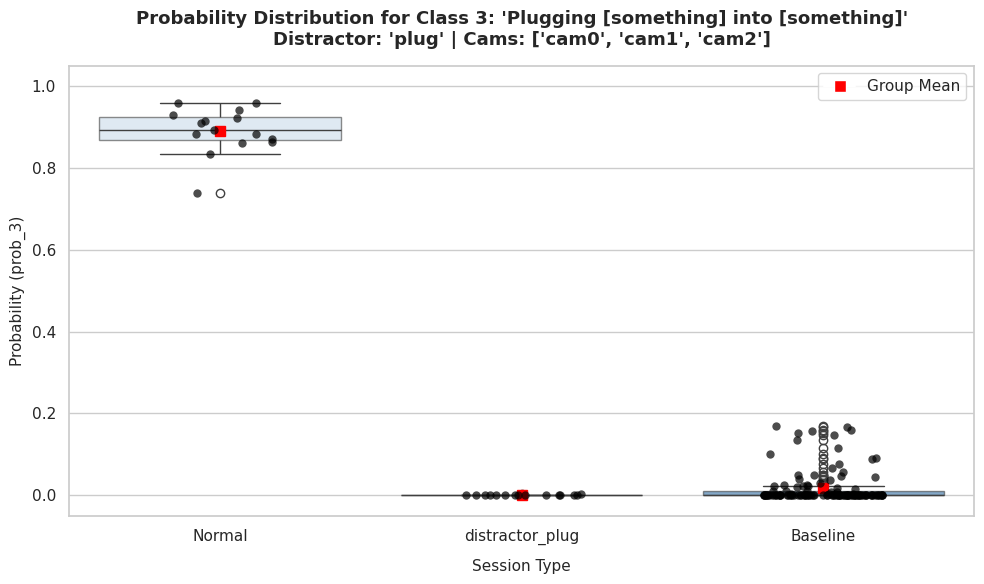

In [87]:
plot_prob_distribution(df, distractor='plug', label=3, id2label_list=id2label_list, cams=['cam0','cam1','cam2'])